# Personalised Movie Recommendation System

**Machine Learning Project | MovieLens `ml-latest-small` | Collaborative Filtering**

**Dataset:** GroupLens Research, University of Minnesota

**Research task:** Recommend **five unrated movies** based on a user's previous movie ratings.  

**Methods:** Regularised bias baseline, user-based *k*-nearest-neighbours (KNN), and biased matrix factorisation (MF).

**Abstract:** This study develops and compares three models for predicting movie preferences from explicit MovieLens ratings. Data cleaning, univariate and bivariate EDA, and sparsity analysis establish the data characteristics. Chronological user-level training, validation and test partitions support transparent model comparison. The primary selection criterion is **Precision@5**, accompanied by Recall@5, NDCG@5, Hit Rate@5, RMSE and MAE. The selected model generates five as-yet-unrated recommendations for an existing user; an optional genre-assisted neighbourhood method supports a new user who supplies sample ratings.



## 1. Introduction, problem statement and research objectives

### 1.1 Background and business problem

An online catalogue can offer thousands of movies while each user has rated only a small fraction. Showing the same popular titles to everybody ignores differences in personal taste. A **collaborative-filtering recommender** instead learns from correlations between users' historical ratings and recommends films a particular user has not rated.

The MovieLens `ml-latest-small` dataset includes ratings, movie titles/genres, free-text tags and external links. It represents ratings collected between 1996 and 2018. It contains **no demographic characteristics and no movie-watching logs**. Ratings indicate expressed preferences, not confirmed viewing behaviour or online clicks.

### 1.2 Central research question

**Which of a regularised bias baseline, user-based KNN, and biased matrix factorisation most effectively retrieves five positively rated but withheld movies, using the same MovieLens training, validation and test protocol?**

### 1.3 Objectives

1. Audit, clean and safely combine four MovieLens data tables, justifying decisions on missing values and duplicates.
2. Characterise distributions, relationships, movie popularity, genres, time and interaction sparsity using **univariate and bivariate EDA**.
3. Implement a non-personalised bias baseline and **two collaborative-filtering methods** with accessible code.
4. Select the best **collaborative** model configuration by **validation Precision@5**, using NDCG@5 and RMSE as tie-breakers; compare against a non-eligible bias baseline.
5. Report held-out rating error and top-five retrieval performance using a consistent candidate set.
6. Demonstrate five genuinely unseen suggestions and an optional onboarding strategy for new users.
7. Discuss methodological limitations, practical implications and realistic future research.

### 1.4 Research expectation

Collaborative models are expected to improve **personalisation** over a rating-bias baseline, but lower RMSE does not necessarily imply higher Precision@5. This is a hypothesis to investigate, not an assumed result.

## 2. Academic and methodological context

- **Collaborative filtering** relies on interactions between users and items rather than requiring film plots or actor metadata. User-based methods identify similar viewers; latent-factor models infer shared preference dimensions.
- **Regularisation** limits overfitting to sparse rating histories, especially for movies rated only a few times.
- **Evaluation must match the task.** RMSE and MAE measure star-rating prediction error, while Precision@5 and related metrics measure retrieval of positively rated items among the five recommendations.
- **MovieLens ratings are observational and missing-not-at-random.** An unseen rating does **not** mean a user dislikes a movie, and this offline experiment is not a causal test of user satisfaction.

**Literature grounding:** Harper and Konstan (2015) describe the MovieLens data; Herlocker et al. (2004) discuss recommender evaluation; Koren, Bell and Volinsky (2009) explain matrix factorisation. Full citations and verified links appear in §15.

### Data dictionary

| File | Key fields | Role |
|---|---|---|
| `ratings.csv` | `userId`, `movieId`, `rating`, `timestamp` | Training and evaluation observations |
| `movies.csv` | `movieId`, `title`, `genres` | Human-readable catalogue, optional genre features |
| `tags.csv` | `userId`, `movieId`, `tag`, `timestamp` | Contextual metadata; not treated as additional ratings |
| `links.csv` | `movieId`, `imdbId`, `tmdbId` | External identifiers only |

A rating ranges from **0.5 to 5.0 stars** in half-star increments. The `timestamp` indicates when a rating was recorded, **not** when a film was watched.

## 3. Tools, configuration and reproducibility

The core dependencies are `numpy`, `pandas`, `scipy`, `matplotlib`, `scikit-learn`, and Jupyter. The study uses a seeded random number generator, standard CSVs, and explicit Python classes. Training, tuning and prediction do **not** depend on external scripts, pre-trained models, paid services or network requests.

In [ ]:
from pathlib import Path
from zipfile import ZipFile
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

RANDOM_SEED = 42
TOP_K = 5
RELEVANCE_THRESHOLD = 4.0
MIN_ITEM_RATINGS = 5

ROOT = Path.cwd ()
ZIP_PATH = ROOT / "ml-latest-small.zip"
RAW_DIR = ROOT / "data" / "raw"
OUTPUT_DIR = ROOT / "outputs"
RAW_DIR.mkdir (parents = True, exist_ok = True)
OUTPUT_DIR.mkdir (parents = True, exist_ok = True)

pd.set_option ("display.max_columns", 25)
pd.set_option ("display.width", 120)
plt.rcParams.update ({"figure.figsize": (9, 4.5), "axes.grid": False})

print ("Python:", platform.python_version ())
print ("NumPy:", np.__version__, "| Pandas:", pd.__version__)
print ("Dataset ZIP:", ZIP_PATH)

Python: 3.13.18
NumPy: 2.4.6 | Pandas: 2.2.3
Dataset ZIP: /content/ml-latest-small.zip


## 4. Extraction, loading and data-quality audit

**Correct workflow order:** Extract → Load → Inspect → Clean and validate → Merge safely → EDA → Split → Fit → Validate → Test → Recommend.

We extract only the five expected files from the supplied archive, avoiding accidental extraction of untrusted paths. The four CSVs are inspected separately before any joins.

In [ ]:
if not ZIP_PATH.is_file ():
    raise FileNotFoundError (
        "Place the supplied ml-latest-small.zip in the same folder as this notebook."
    )

expected_files = ["ratings.csv", "movies.csv", "tags.csv", "links.csv", "README.txt"]

with ZipFile (ZIP_PATH, mode = "r") as archive:
    for filename in expected_files:
        archive_name = f"ml-latest-small/{filename}"
        with archive.open (archive_name) as source:
            (RAW_DIR / filename).write_bytes (source.read ())

ratings_raw = pd.read_csv (RAW_DIR / "ratings.csv")
movies_raw = pd.read_csv (RAW_DIR / "movies.csv")
tags_raw = pd.read_csv (RAW_DIR / "tags.csv")
links_raw = pd.read_csv (RAW_DIR / "links.csv")

source_tables = {
    "Ratings": ratings_raw,
    "Movies": movies_raw,
    "Tags": tags_raw,
    "Links": links_raw
}

source_audit = pd.DataFrame ([
    {
        "Table": name,
        "Rows": len (table),
        "Columns": len (table.columns),
        "Null cells": int (table.isna ().sum ().sum ()),
        "Exact duplicate rows": int (table.duplicated ().sum ())
    }
    for name, table in source_tables.items ()
])

display (source_audit)
print ("Repeated user–movie rating pairs:",
       ratings_raw.duplicated (subset = ["userId", "movieId"]).sum ())

for name, table in source_tables.items ():
    print (f"\n{name} | Data types:", table.dtypes.astype (str).to_dict ())
    display (table.head (3))

,Table,Rows,Columns,Null cells,Exact duplicate rows
0,Ratings,100836,4,0,0
1,Movies,9742,3,0,0
2,Tags,3683,4,0,0
3,Links,9742,3,8,0


Repeated user–movie rating pairs: 0

Ratings | Data types: {'userId': 'int64', 'movieId': 'int64', 'rating': 'float64', 'timestamp': 'int64'}


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224



Movies | Data types: {'movieId': 'int64', 'title': 'object', 'genres': 'object'}


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance



Tags | Data types: {'userId': 'int64', 'movieId': 'int64', 'tag': 'object', 'timestamp': 'int64'}


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992



Links | Data types: {'movieId': 'int64', 'imdbId': 'int64', 'tmdbId': 'float64'}


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0


### 4.1 Cleaning decisions and duplicate policy

- **Legitimate repeat opinions:** Ratings by *different* users for the same movie are distinct observations; removing them would destroy the signal collaborative filtering needs.
- **Exact duplicates:** Remove exact duplicate rows, which add no new information.
- **Conflicting `(userId, movieId)` pairs:** If they exist, keep the row with the **latest** rating timestamp, so each user–movie interaction has one preference target. This is not necessary for the supplied file, but the rule is explicit.
- **Invalid ratings or identifiers:** Discard ratings outside 0.5–5.0, not in 0.5 increments, with invalid IDs, or referencing a missing movie.
- **Missing optional information:** Missing IMDb/TMDB IDs are preserved as missing values; absence of a link is not a reason to remove a film.
- **Tags:** Never join one tag row per movie directly into ratings, because multiple tags could artificially multiply rating records.

In [ ]:
ratings = ratings_raw.drop_duplicates ().copy ()
movies = movies_raw.drop_duplicates ().copy ()
tags = tags_raw.drop_duplicates ().copy ()
links = links_raw.drop_duplicates ().copy ()

for column in ["userId", "movieId", "rating", "timestamp"]:
    ratings[column] = pd.to_numeric (ratings[column], errors = "coerce")

rating_is_valid = (
    ratings[["userId", "movieId", "rating", "timestamp"]].notna ().all (axis = 1)
    & ratings["userId"].ge (1)
    & ratings["movieId"].ge (1)
    & ratings["rating"].between (0.5, 5.0)
    & np.isclose (ratings["rating"] * 2, np.round (ratings["rating"] * 2))
    & np.isclose (ratings["userId"], np.round (ratings["userId"]))
    & np.isclose (ratings["movieId"], np.round (ratings["movieId"]))
)

invalid_rating_rows = int ((~rating_is_valid).sum ())
ratings = ratings.loc[rating_is_valid].copy ()
ratings = ratings.sort_values (["userId", "movieId", "timestamp"])
ratings = ratings.drop_duplicates (["userId", "movieId"], keep = "last")

for column in ["userId", "movieId", "timestamp"]:
    ratings[column] = ratings[column].astype ("int64")

movies["movieId"] = pd.to_numeric (movies["movieId"], errors = "coerce")
movies = movies.dropna (subset = ["movieId", "title"]).copy ()
movies["movieId"] = movies["movieId"].astype ("int64")
movies["title"] = movies["title"].astype (str).str.strip ()
movies["genres"] = movies["genres"].fillna ("(no genres listed)")
movies = movies.loc[movies["title"].ne ("")]
movies = movies.drop_duplicates (subset = ["movieId"], keep = "first")

ratings_not_in_catalogue = int ((~ratings["movieId"].isin (movies["movieId"])).sum ())
ratings = ratings.loc[ratings["movieId"].isin (movies["movieId"])].copy ()
ratings["rated_at_utc"] = pd.to_datetime (ratings["timestamp"], unit = "s", utc = True)

for table in [tags, links]:
    table["movieId"] = pd.to_numeric (table["movieId"], errors = "coerce")
    table.dropna (subset = ["movieId"], inplace = True)
    table["movieId"] = table["movieId"].astype ("int64")

links = links.drop_duplicates (subset = ["movieId"], keep = "first")
tags["tag"] = tags["tag"].fillna ("").astype (str).str.strip ()
tags = tags.loc[tags["tag"].ne ("")]

assert not ratings.duplicated (["userId", "movieId"]).any ()
assert ratings["rating"].between (0.5, 5.0).all ()

print ("Invalid rating rows removed:", invalid_rating_rows)
print ("Ratings without matching movie metadata:", ratings_not_in_catalogue)
print ("Cleaned ratings:", len (ratings), "| Movies:", len (movies))
print ("Users:", ratings["userId"].nunique (), "| Rated movies:", ratings["movieId"].nunique ())

Invalid rating rows removed: 0
Ratings without matching movie metadata: 0
Cleaned ratings: 100836 | Movies: 9742
Users: 610 | Rated movies: 9724


### 4.2 Correctly joining the datasets

We first combine *one row per movie* from movie titles, links and **aggregated** tag counts. We then join this catalogue to ratings with `validate = "many_to_one"`. Ratings are the modelling unit: the merge must not create or delete interactions.

In [ ]:
tag_summary = (
    tags.groupby ("movieId", as_index = False)
    .agg (tag_count = ("tag", "size"), unique_tags = ("tag", "nunique"))
)

movie_catalog = (
    movies.merge (links, on = "movieId", how = "left", validate = "one_to_one")
    .merge (tag_summary, on = "movieId", how = "left", validate = "one_to_one")
)

for column in ["tag_count", "unique_tags"]:
    movie_catalog[column] = movie_catalog[column].fillna (0).astype ("int64")

ratings_enriched = ratings.merge (
    movie_catalog, on = "movieId", how = "left", validate = "many_to_one"
)

assert len (ratings_enriched) == len (ratings)
assert ratings_enriched["title"].notna ().all ()
assert movie_catalog["movieId"].is_unique

print ("Merged rating rows:", len (ratings_enriched))
display (ratings_enriched.head ())

ratings.to_csv (OUTPUT_DIR / "cleaned_ratings.csv", index = False)
movie_catalog.to_csv (OUTPUT_DIR / "cleaned_movie_catalog.csv", index = False)

Merged rating rows: 100836


,userId,movieId,rating,timestamp,rated_at_utc,title,genres,imdbId,tmdbId,tag_count,unique_tags
0,1,1,4.0,964982703,2000-07-30 18:45:03+00:00,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,114709,862.0,3,2
1,1,3,4.0,964981247,2000-07-30 18:20:47+00:00,Grumpier Old Men (1995),Comedy|Romance,113228,15602.0,2,2
2,1,6,4.0,964982224,2000-07-30 18:37:04+00:00,Heat (1995),Action|Crime|Thriller,113277,949.0,0,0
3,1,47,5.0,964983815,2000-07-30 19:03:35+00:00,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,114369,807.0,3,3
4,1,50,5.0,964982931,2000-07-30 18:48:51+00:00,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,114814,629.0,6,6


## 5. Exploratory Data Analysis (EDA)

EDA is separated from modelling: these **descriptive charts** use the cleaned complete data to describe the supplied snapshot. After this section, the model-selection candidate set and all fitted parameters are derived **only from training data**, not from the EDA aggregates.

### 5.1 Basic statistics and user–movie matrix sparsity

Sparsity = 1 − (number of observed ratings ÷ number of possible user–movie pairs). High sparsity makes neighbourhood overlap rare and motivates regularisation and careful evaluation.

In [ ]:
user_activity = ratings.groupby ("userId").size ()
movie_activity = ratings.groupby ("movieId").size ()

n_users = ratings["userId"].nunique ()
n_rated_items = ratings["movieId"].nunique ()
possible_pairs = n_users * n_rated_items
sparsity_pct = 100 * (1 - len (ratings) / possible_pairs)

summary = pd.DataFrame ({
    "Statistic": [
        "Cleaned ratings", "Unique users", "Catalogue movies", "Rated movies",
        "Average rating", "Median rating", "Matrix sparsity (%)",
        "Median ratings per user", "Median ratings per rated movie"
    ],
    "Value": [
        len (ratings), n_users, len (movie_catalog), n_rated_items,
        ratings["rating"].mean (), ratings["rating"].median (), sparsity_pct,
        user_activity.median (), movie_activity.median ()
    ]
})
display (summary.round (3))

### 5.2 Univariate analysis: distribution of rating scores

A rating histogram identifies whether users use the scale evenly or favour particular star values. This also informs the later threshold for a positive held-out rating (`≥ 4.0`).

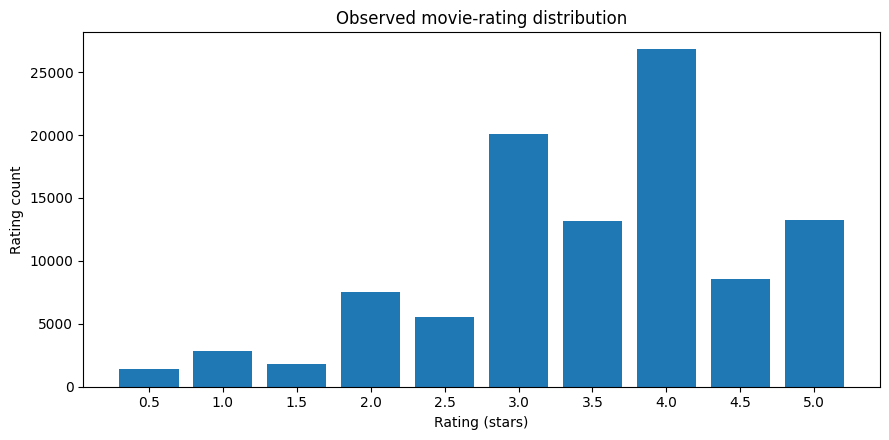

In [ ]:
rating_distribution = ratings["rating"].value_counts ().sort_index ()

fig, ax = plt.subplots (figsize = (9, 4.5))
ax.bar (rating_distribution.index.astype (str), rating_distribution.values)
ax.set (title = "Observed movie-rating distribution", xlabel = "Rating (stars)", ylabel = "Rating count")
plt.tight_layout ()
plt.show ()

### 5.3 Univariate analysis: user activity and movie popularity

Movies typically follow a long-tail distribution: many titles have few ratings and a smaller number are rated frequently. A user with few interactions is more difficult to match to neighbours.

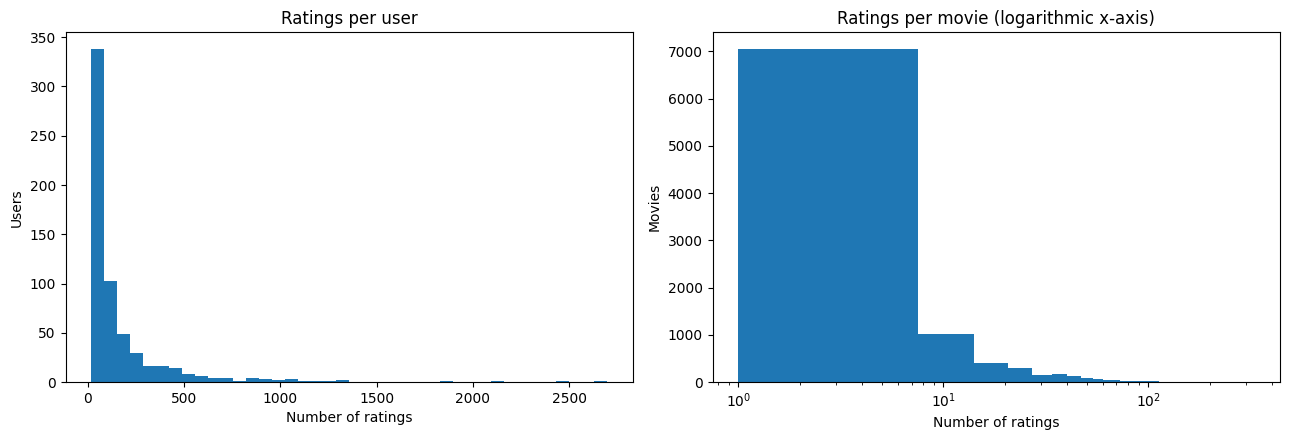

In [ ]:
fig, axes = plt.subplots (1, 2, figsize = (13, 4.5))
axes[0].hist (user_activity, bins = 40)
axes[0].set (title = "Ratings per user", xlabel = "Number of ratings", ylabel = "Users")
axes[1].hist (movie_activity, bins = 50)
axes[1].set_xscale ("log")
axes[1].set (title = "Ratings per movie (logarithmic x-axis)", xlabel = "Number of ratings", ylabel = "Movies")
plt.tight_layout ()
plt.show ()

### 5.4 Bivariate analysis: movie popularity versus its mean rating

A title with one enthusiastic rating may have a higher mean than a film with hundreds of strong ratings. The scatter plot relates **popularity (count)** to **average score**, without treating it as causal evidence.

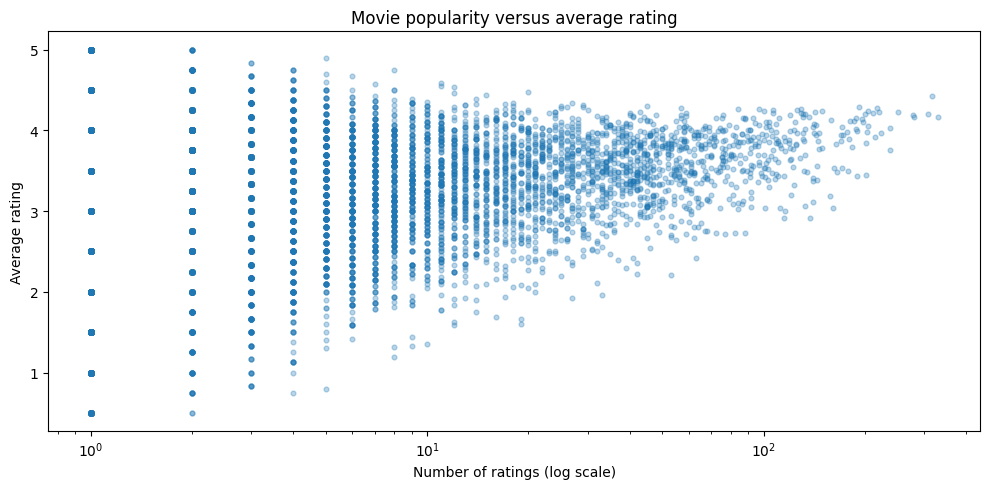

,title,rating_count,mean_rating
314,Forrest Gump (1994),329,4.16
277,"Shawshank Redemption, The (1994)",317,4.43
257,Pulp Fiction (1994),307,4.20
510,"Silence of the Lambs, The (1991)",279,4.16
1938,"Matrix, The (1999)",278,4.19
224,Star Wars: Episode IV - A New Hope (1977),251,4.23
418,Jurassic Park (1993),238,3.75
97,Braveheart (1995),237,4.03
507,Terminator 2: Judgment Day (1991),224,3.97
461,Schindler's List (1993),220,4.22


In [ ]:
movie_statistics = (
    ratings.groupby ("movieId", as_index = False)
    .agg (rating_count = ("rating", "size"), mean_rating = ("rating", "mean"))
    .merge (movies[["movieId", "title"]], on = "movieId", how = "left")
)

fig, ax = plt.subplots (figsize = (10, 5))
ax.scatter (movie_statistics["rating_count"], movie_statistics["mean_rating"], alpha = 0.30, s = 12)
ax.set_xscale ("log")
ax.set (title = "Movie popularity versus average rating", xlabel = "Number of ratings (log scale)", ylabel = "Average rating")
plt.tight_layout ()
plt.show ()

display (movie_statistics.nlargest (10, "rating_count")[["title", "rating_count", "mean_rating"]].round (2))

### 5.5 Univariate genre frequency and bivariate genre–rating association

MovieLens gives many films multiple genres. Genre counts therefore overlap. Average ratings by genre are descriptive **associations**, not evidence that a genre causes high ratings; prolific users and popular titles contribute repeated observations.

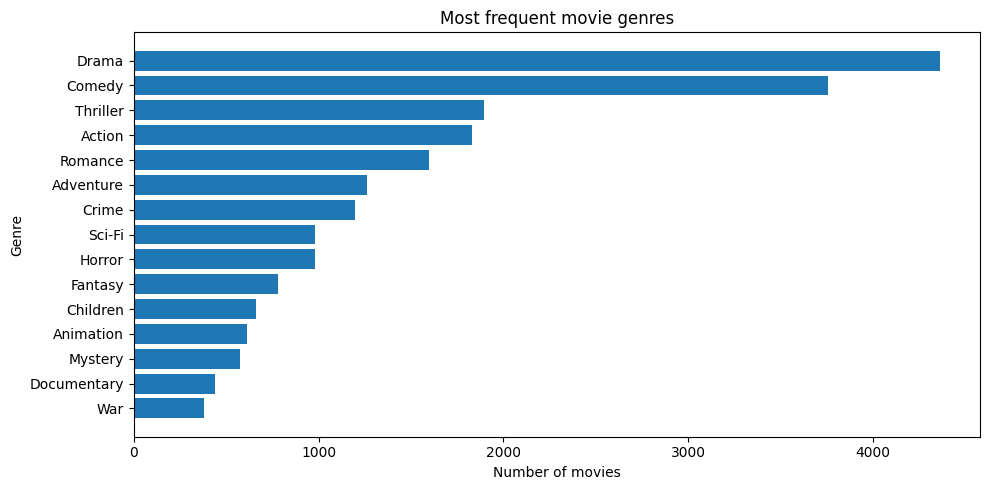

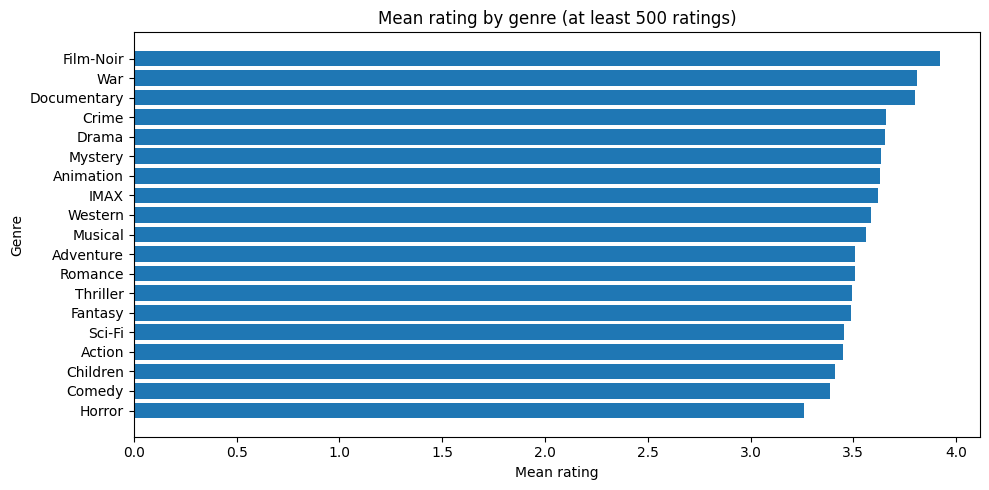

In [ ]:
movie_genres = movie_catalog[["movieId", "genres"]].copy ()
movie_genres["genre"] = movie_genres["genres"].str.split ("|")
movie_genres = movie_genres.explode ("genre")
movie_genres = movie_genres.loc[movie_genres["genre"].ne ("(no genres listed)")]

genre_frequency = movie_genres["genre"].value_counts ().head (15)

fig, ax = plt.subplots (figsize = (10, 5))
ax.barh (genre_frequency.index[::-1], genre_frequency.values[::-1])
ax.set (title = "Most frequent movie genres", xlabel = "Number of movies", ylabel = "Genre")
plt.tight_layout ()
plt.show ()

genre_ratings = ratings[["movieId", "rating"]].merge (
    movie_genres[["movieId", "genre"]], on = "movieId", how = "inner"
)
genre_rating_summary = (
    genre_ratings.groupby ("genre")
    .agg (rating_count = ("rating", "size"), mean_rating = ("rating", "mean"))
    .query ("rating_count >= 500")
    .sort_values ("mean_rating")
)

fig, ax = plt.subplots (figsize = (10, 5))
ax.barh (genre_rating_summary.index, genre_rating_summary["mean_rating"])
ax.set (title = "Mean rating by genre (at least 500 ratings)", xlabel = "Mean rating", ylabel = "Genre")
plt.tight_layout ()
plt.show ()

### 5.6 Timestamp patterns, user–movie interactions and EDA interpretation

Year of rating is **not** movie release year. The heatmap below visualises *whether* an interaction exists, not missing ratings encoded as actual zero-star opinions.

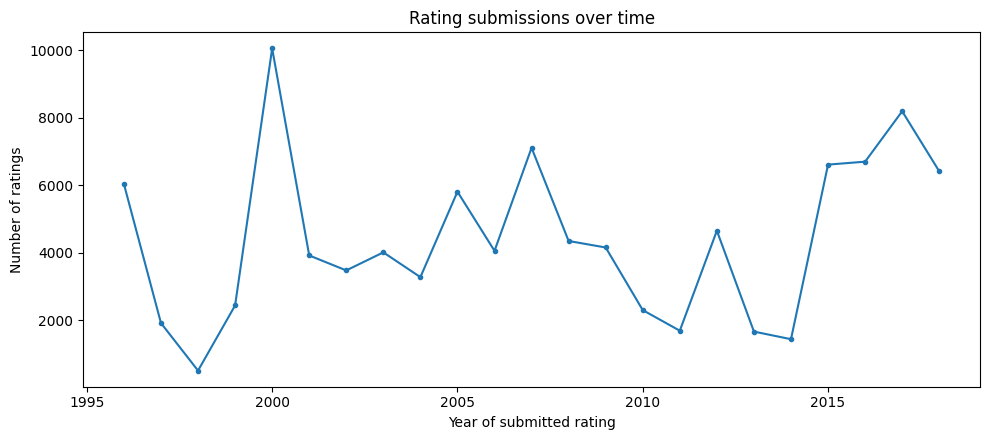

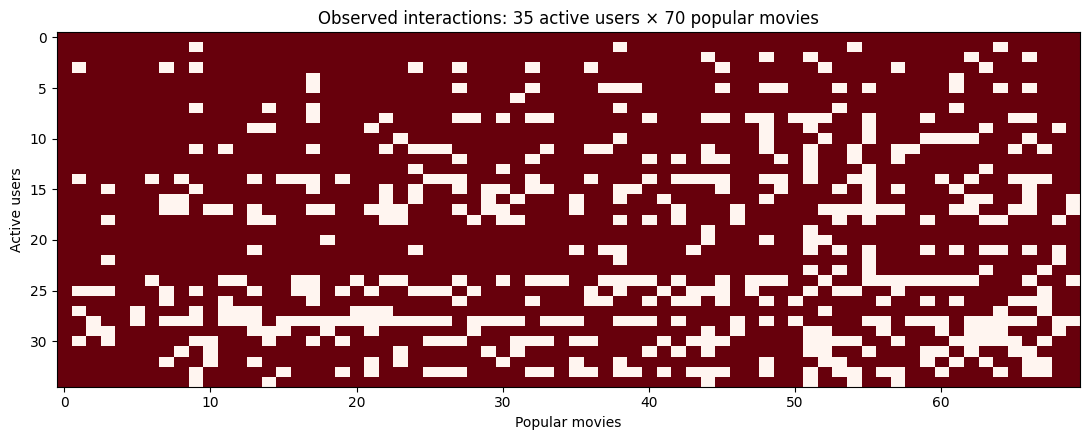

Key EDA finding: 98.30% of rated-movie/user pairs are unobserved.
Rating mode: 4.0 stars.
Most rated movie: Forrest Gump (1994).


In [ ]:
ratings_by_year = ratings.groupby (ratings["rated_at_utc"].dt.year).size ()

fig, ax = plt.subplots (figsize = (10, 4.5))
ax.plot (ratings_by_year.index, ratings_by_year.values, marker = "o", markersize = 3)
ax.set (title = "Rating submissions over time", xlabel = "Year of submitted rating", ylabel = "Number of ratings")
plt.tight_layout ()
plt.show ()

active_user_ids = user_activity.nlargest (35).index
popular_item_ids = movie_activity.nlargest (70).index
interaction_subset = ratings.loc[
    ratings["userId"].isin (active_user_ids)
    & ratings["movieId"].isin (popular_item_ids)
]
interaction_heat = (
    interaction_subset.assign (observed = 1)
    .pivot (index = "userId", columns = "movieId", values = "observed")
    .reindex (index = active_user_ids, columns = popular_item_ids)
    .fillna (0)
)

fig, ax = plt.subplots (figsize = (11, 4.5))
ax.imshow (interaction_heat.to_numpy (), aspect = "auto", interpolation = "nearest", cmap = "Reds")
ax.set (title = "Observed interactions: 35 active users × 70 popular movies", xlabel = "Popular movies", ylabel = "Active users")
plt.tight_layout ()
plt.show ()

print (f"Key EDA finding: {sparsity_pct:.2f}% of rated-movie/user pairs are unobserved.")
print (f"Rating mode: {rating_distribution.idxmax ():.1f} stars.")
print (f"Most rated movie: {movie_statistics.nlargest (1, 'rating_count')['title'].iloc[0]}.")

## 6. Experimental methodology: split and evaluation design

### 6.1 Leakage-aware split

For every user, sort their ratings by recorded timestamp (then `movieId` for stable ordering), and take approximately:

- **70% oldest ratings:** training;
- **10% next ratings:** validation (model/hyperparameter selection);
- **20% newest ratings:** untouched test (final evaluation only).

MovieLens guarantees at least 20 ratings per user, so each user has records in every partition. This is a **per-user chronological** split, not a globally chronological forecasting experiment; users can have different calendar dates. EDA descriptive aggregates from §5 are not supplied as model features.

### 6.2 Equal candidate pool for all models

Eligible recommendation candidates are movies with **at least five ratings in the *training* partition**. This threshold is fixed from the initial training set and reused for both validation and test, preventing an evaluation rule learned from test outcomes. For each user, remove any items already observed in that user's corresponding model-training history.

For validation, only training ratings are known. For test, models are **refitted on training + validation**, and only those interactions are considered known. A withheld movie must be both eligible and rated at least **4.0** in the relevant holdout to count as a hit.

This full-eligible-catalogue ranking is more difficult than artificially sampling a handful of unrated items as negatives. Unobserved films are **unknown**, not proven dislikes, making the metrics conservative *observational proxies*.

### 6.3 Metrics

- **RMSE:** $\sqrt{\frac{1}{N}\sum(r_{ui}-\hat r_{ui})^2}$, in rating stars; lower is better.
- **MAE:** $\frac{1}{N}\sum|r_{ui}-\hat r_{ui}|$, in rating stars; lower is better.
- **Precision@5:** relevant retrieved titles divided by five, averaged over eligible users.
- **Recall@5:** relevant retrieved titles divided by the number of eligible withheld relevant titles, averaged over eligible users.
- **Hit Rate@5:** fraction of eligible users receiving at least one relevant title.
- **NDCG@5:** discounted gain in ranks 1–5, divided by the best possible discounted gain for that user's eligible relevant titles.

Only users with at least one **eligible** relevant held-out rating enter the ranking-metric average. The number of such users is reported. Rating-error metrics include all held-out interactions, using global/user/item bias fallbacks for unseen items.

In [ ]:
ordered = ratings.sort_values (["userId", "timestamp", "movieId"]).copy ()
ordered["within_user_index"] = ordered.groupby ("userId").cumcount ()
ordered["within_user_total"] = ordered.groupby ("userId")["movieId"].transform ("size")

n_train = np.floor (0.70 * ordered["within_user_total"]).astype (int)
n_valid = np.maximum (1, np.floor (0.10 * ordered["within_user_total"]).astype (int))

train_mask = ordered["within_user_index"] < n_train
valid_mask = (
    (ordered["within_user_index"] >= n_train)
    & (ordered["within_user_index"] < n_train + n_valid)
)
test_mask = ~(train_mask | valid_mask)

columns = ["userId", "movieId", "rating", "timestamp"]
train = ordered.loc[train_mask, columns].reset_index (drop = True)
valid = ordered.loc[valid_mask, columns].reset_index (drop = True)
test = ordered.loc[test_mask, columns].reset_index (drop = True)
train_valid = pd.concat ([train, valid], ignore_index = True)

assert len (train) + len (valid) + len (test) == len (ratings)
assert not (set (zip (train.userId, train.movieId)) & set (zip (valid.userId, valid.movieId)))
assert not (set (zip (train_valid.userId, train_valid.movieId)) & set (zip (test.userId, test.movieId)))
assert set (train.userId) == set (valid.userId) == set (test.userId)

user_ids = np.sort (ratings["userId"].unique ())
item_ids = np.sort (movies["movieId"].unique ())
item_index = pd.Index (item_ids)
user_index = pd.Index (user_ids)

train_item_counts = train.groupby ("movieId").size ()
eligible_item_ids = np.sort (train_item_counts.loc[train_item_counts >= MIN_ITEM_RATINGS].index.to_numpy ())
eligible_item_positions = item_index.get_indexer (eligible_item_ids)

split_table = pd.DataFrame ({
    "Partition": ["Training", "Validation", "Test"],
    "Ratings": [len (train), len (valid), len (test)]
})
split_table["Percentage"] = 100 * split_table["Ratings"] / len (ratings)
display (split_table.round (2))

print ("Candidate movies (at least five TRAIN ratings):", len (eligible_item_ids))
print ("Per-user chronological split complete. All users have training history.")

,Partition,Ratings,Percentage
0,Training,70312,69.73
1,Validation,9818,9.74
2,Test,20706,20.53


Candidate movies (at least five TRAIN ratings): 2757
Per-user chronological split complete. All users have training history.


## 7. Machine learning model development

All core models take `fit (observed_ratings, user_ids, item_ids)` and expose `score_matrix ()` and `predict (heldout_ratings)`. A lightweight, validation-calibrated collaborative wrapper blends KNN/MF residuals with the bias prior to reduce noisy top-ranked predictions from rarely rated films.

### 7.1 Baseline: regularised global, user and movie effects

$$\widehat r_{ui}=\mu+b_u+b_i.$$

The global mean $\mu$ is corrected by a user's generosity $b_u$ and a movie's general reception $b_i$. Alternating, **shrunken** mean updates prevent rare users/items from receiving extreme effects. This baseline is a required control: personalised models should improve on more than a globally popular-film list.

In [ ]:
class BiasBaseline:
    """Regularised user/movie bias estimates with safe unknown-ID fallback."""

    def __init__ (self, regularisation = 12.0, iterations = 10):
        self.regularisation = float (regularisation)
        self.iterations = int (iterations)

    def fit (self, observations, user_ids, item_ids):
        self.user_ids = np.asarray (user_ids, dtype = int)
        self.item_ids = np.asarray (item_ids, dtype = int)
        self.user_index = pd.Index (self.user_ids)
        self.item_index = pd.Index (self.item_ids)

        u = self.user_index.get_indexer (observations["userId"])
        i = self.item_index.get_indexer (observations["movieId"])
        if (u < 0).any () or (i < 0).any ():
            raise ValueError ("Training IDs must belong to the supplied universe.")

        y = observations["rating"].to_numpy (dtype = float)
        self.global_mean = float (y.mean ())
        self.user_bias = np.zeros (len (self.user_ids), dtype = float)
        self.item_bias = np.zeros (len (self.item_ids), dtype = float)

        user_counts = np.bincount (u, minlength = len (self.user_ids))
        item_counts = np.bincount (i, minlength = len (self.item_ids))

        for _ in range (self.iterations):
            user_residual = y - self.global_mean - self.item_bias[i]
            self.user_bias = (
                np.bincount (u, weights = user_residual, minlength = len (self.user_ids))
                / (user_counts + self.regularisation)
            )

            item_residual = y - self.global_mean - self.user_bias[u]
            self.item_bias = (
                np.bincount (i, weights = item_residual, minlength = len (self.item_ids))
                / (item_counts + self.regularisation)
            )

        return self

    def predict_raw (self, observations):
        users = self.user_index.get_indexer (observations["userId"])
        items = self.item_index.get_indexer (observations["movieId"])
        user_offsets = np.zeros (len (observations), dtype = float)
        item_offsets = np.zeros (len (observations), dtype = float)
        known_users = users >= 0
        known_items = items >= 0
        user_offsets[known_users] = self.user_bias[users[known_users]]
        item_offsets[known_items] = self.item_bias[items[known_items]]
        return self.global_mean + user_offsets + item_offsets

    def predict (self, observations):
        return np.clip (self.predict_raw (observations), 0.5, 5.0)

    def score_matrix (self):
        return (
            self.global_mean
            + self.user_bias[:, None]
            + self.item_bias[None, :]
        ).astype ("float32")

### 7.2 User-based KNN collaborative filtering

Users become similar when their **observed baseline-adjusted rating residuals** point in similar directions. We compute sparse cosine similarity, downweight similarity based on only a few co-rated titles, ignore negative similarities, and retain at most $k$ positive neighbours per user.

$$\widehat r_{ui}=\underbrace{(\mu+b_u+b_i)}_{\text{bias baseline}}+\frac{\sum_{v\in N_k(u),\,v\text{ rated }i}w_{uv}(r_{vi}-\widehat r^{\mathrm{base}}_{vi})}{\sum_{v\in N_k(u),\,v\text{ rated }i}|w_{uv}|}.$$

When no relevant neighbour rated a movie, the model falls back to the regularised baseline. Similarity and normalisers are constructed exclusively from the current **fit partition**. Sparse zeros indicate **unobserved residuals**; they are never recorded as zero-star movie ratings.

In [ ]:
class UserKNN:
    """Sparse user-user collaborative filtering with overlap shrinkage."""

    def __init__ (self, neighbours = 35, shrinkage = 12.0, minimum_overlap = 2):
        self.neighbours = int (neighbours)
        self.shrinkage = float (shrinkage)
        self.minimum_overlap = int (minimum_overlap)

    def fit (self, observations, user_ids, item_ids):
        self.baseline = BiasBaseline ().fit (observations, user_ids, item_ids)
        self.user_index = self.baseline.user_index
        self.item_index = self.baseline.item_index
        n_users = len (user_ids)
        n_items = len (item_ids)

        users = self.user_index.get_indexer (observations["userId"])
        items = self.item_index.get_indexer (observations["movieId"])
        residuals = observations["rating"].to_numpy () - self.baseline.predict_raw (observations)

        self.residual_matrix = sparse.csr_matrix (
            (residuals, (users, items)), shape = (n_users, n_items)
        )
        self.observed_matrix = sparse.csr_matrix (
            (np.ones (len (observations)), (users, items)), shape = (n_users, n_items)
        )

        norms = np.sqrt (np.asarray (self.residual_matrix.power (2).sum (axis = 1)).ravel ())
        normalised = sparse.diags (1.0 / np.maximum (norms, 1e-10)) @ self.residual_matrix
        similarity = (normalised @ normalised.T).toarray ()
        common_counts = (self.observed_matrix @ self.observed_matrix.T).toarray ()

        similarity *= common_counts / (common_counts + self.shrinkage)
        similarity[common_counts < self.minimum_overlap] = 0.0
        similarity = np.maximum (similarity, 0.0)
        np.fill_diagonal (similarity, 0.0)

        row_indices = []
        col_indices = []
        values = []

        for user_pos in range (n_users):
            neighbour_candidates = np.argsort (-similarity[user_pos])[:self.neighbours]
            neighbour_candidates = neighbour_candidates[
                similarity[user_pos, neighbour_candidates] > 0
            ]
            row_indices.extend ([user_pos] * len (neighbour_candidates))
            col_indices.extend (neighbour_candidates.tolist ())
            values.extend (similarity[user_pos, neighbour_candidates].tolist ())

        self.weights = sparse.csr_matrix (
            (values, (row_indices, col_indices)), shape = (n_users, n_users)
        )

        weighted_residuals = (self.weights @ self.residual_matrix).toarray ()
        neighbour_support = (self.weights @ self.observed_matrix).toarray ()
        adjustment = np.divide (
            weighted_residuals, neighbour_support,
            out = np.zeros_like (weighted_residuals), where = neighbour_support > 1e-12
        )
        self.raw_scores = self.baseline.score_matrix () + adjustment.astype ("float32")
        return self

    def score_matrix (self):
        return self.raw_scores

    def predict (self, observations):
        u = self.user_index.get_indexer (observations["userId"])
        i = self.item_index.get_indexer (observations["movieId"])
        predictions = self.baseline.predict_raw (observations)
        known = (u >= 0) & (i >= 0)
        predictions[known] = self.raw_scores[u[known], i[known]]
        return np.clip (predictions, 0.5, 5.0)

### 7.3 Biased matrix factorisation (observed-only SGD)

This latent-factor model learns a $d$-dimensional vector for each user ($p_u$) and movie ($q_i$):

$$\widehat r_{ui}=\mu+b_u+b_i+p_u^\top q_i.$$

For **observed** training ratings only, it minimises squared error plus L2 penalties on biases and latent factors. A reproducible mini-batch stochastic-gradient procedure updates users and items; the model never fills missing ratings with zeros or pretends they are negative examples.

Validation RMSE chooses the number of training epochs for a given MF configuration. Training and validation errors are logged for the learning curve. After validation, the selected epoch is reused for test-stage refitting; the test data are never used for early stopping.

In [ ]:
class BiasedMatrixFactorisation:
    """Observed-only, regularised mini-batch SGD for explicit movie ratings."""

    def __init__ (
        self, factors = 18, epochs = 22, learning_rate = 0.006,
        regularisation = 0.06, batch_size = 1024, seed = 42
    ):
        self.factors = int (factors)
        self.epochs = int (epochs)
        self.learning_rate = float (learning_rate)
        self.regularisation = float (regularisation)
        self.batch_size = int (batch_size)
        self.seed = int (seed)

    def fit (self, observations, user_ids, item_ids, validation = None):
        rng = np.random.default_rng (self.seed)
        self.user_ids = np.asarray (user_ids, dtype = int)
        self.item_ids = np.asarray (item_ids, dtype = int)
        self.user_index = pd.Index (self.user_ids)
        self.item_index = pd.Index (self.item_ids)

        u = self.user_index.get_indexer (observations["userId"])
        i = self.item_index.get_indexer (observations["movieId"])
        y = observations["rating"].to_numpy (dtype = float)
        if (u < 0).any () or (i < 0).any ():
            raise ValueError ("All training IDs must be included in the model universe.")

        initial_baseline = BiasBaseline ().fit (observations, user_ids, item_ids)
        self.global_mean = initial_baseline.global_mean
        self.user_bias = initial_baseline.user_bias.copy ()
        self.item_bias = initial_baseline.item_bias.copy ()
        self.P = rng.normal (0, 0.07, size = (len (user_ids), self.factors))
        self.Q = rng.normal (0, 0.07, size = (len (item_ids), self.factors))

        history = []
        best_validation_rmse = np.inf
        best_state = None
        self.best_epoch = self.epochs

        for epoch in range (1, self.epochs + 1):
            shuffled = rng.permutation (len (y))

            for start in range (0, len (shuffled), self.batch_size):
                batch = shuffled[start:start + self.batch_size]
                ub = u[batch]
                ib = i[batch]
                targets = y[batch]

                old_p = self.P[ub].copy ()
                old_q = self.Q[ib].copy ()
                old_user_bias = self.user_bias[ub].copy ()
                old_item_bias = self.item_bias[ib].copy ()

                estimates = (
                    self.global_mean + old_user_bias + old_item_bias
                    + np.sum (old_p * old_q, axis = 1)
                )
                errors = targets - estimates

                np.add.at (
                    self.P, ub,
                    self.learning_rate * (
                        errors[:, None] * old_q - self.regularisation * old_p
                    )
                )
                np.add.at (
                    self.Q, ib,
                    self.learning_rate * (
                        errors[:, None] * old_p - self.regularisation * old_q
                    )
                )
                np.add.at (
                    self.user_bias, ub,
                    self.learning_rate * (errors - self.regularisation * old_user_bias)
                )
                np.add.at (
                    self.item_bias, ib,
                    self.learning_rate * (errors - self.regularisation * old_item_bias)
                )

            train_error = np.sqrt (mean_squared_error (y, self.predict (observations)))
            row = {"Epoch": epoch, "Training RMSE": float (train_error)}

            if validation is not None:
                validation_error = np.sqrt (
                    mean_squared_error (validation["rating"], self.predict (validation))
                )
                row["Validation RMSE"] = float (validation_error)

                if validation_error < best_validation_rmse:
                    best_validation_rmse = validation_error
                    self.best_epoch = epoch
                    best_state = (
                        self.user_bias.copy (), self.item_bias.copy (),
                        self.P.copy (), self.Q.copy ()
                    )

            history.append (row)

        self.history = pd.DataFrame (history)

        if best_state is not None:
            self.user_bias, self.item_bias, self.P, self.Q = best_state

        return self

    def score_matrix (self):
        return (
            self.global_mean
            + self.user_bias[:, None]
            + self.item_bias[None, :]
            + self.P @ self.Q.T
        ).astype ("float32")

    def predict (self, observations):
        u = self.user_index.get_indexer (observations["userId"])
        i = self.item_index.get_indexer (observations["movieId"])
        results = np.full (len (observations), self.global_mean, dtype = float)
        known_users = u >= 0
        known_items = i >= 0

        results[known_users] += self.user_bias[u[known_users]]
        results[known_items] += self.item_bias[i[known_items]]
        known_pairs = known_users & known_items
        results[known_pairs] += np.sum (
            self.P[u[known_pairs]] * self.Q[i[known_pairs]], axis = 1
        )

        return np.clip (results, 0.5, 5.0)

### 7.4 Regularised ranking calibration for collaborative models

A raw KNN residual may be based on only one neighbour, while a learned MF vector for a rarely rated film is uncertain. **Ranking by such unrestrained estimates over thousands of candidates can over-promote obscure titles.** We therefore compare a small, predefined set of *collaborative residual strengths* $\alpha$, keeping a robust user/movie bias prior. The weights are selected using **validation only**. Both KNN and MF remain genuinely personalised for nonzero $\alpha$.

In [ ]:
class CalibratedCollaborativeModel:
    """Personalised CF residual blended with an independently fitted bias prior."""

    def __init__ (self, core_model, bias_model, collaborative_strength = 0.35):
        self.core_model = core_model
        self.bias_model = bias_model
        self.collaborative_strength = float (collaborative_strength)
        self.user_index = bias_model.user_index
        self.item_index = bias_model.item_index
        self.raw_scores = (
            bias_model.score_matrix ()
            + self.collaborative_strength * (
                core_model.score_matrix () - bias_model.score_matrix ()
            )
        ).astype ("float32")

    def score_matrix (self):
        return self.raw_scores

    def predict (self, observations):
        predictions = self.bias_model.predict_raw (observations)
        u = self.user_index.get_indexer (observations["userId"])
        i = self.item_index.get_indexer (observations["movieId"])
        known = (u >= 0) & (i >= 0)
        predictions[known] = self.raw_scores[u[known], i[known]]
        return np.clip (predictions, 0.5, 5.0)

## 8. Fair offline evaluation implementation

Each fitted model produces **raw, unrounded preference scores** for ranking. Only rating-prediction output is clipped to the scale 0.5–5.0 for RMSE and MAE. This prevents a wall of displayed `5.0` predictions from hiding real ordering differences.

The same evaluation function, eligible catalogue, relevance threshold and user histories are used for all three algorithms. It never requires item genres for existing-user collaborative recommendations.

In [ ]:
def rating_metrics (model, heldout):
    actual = heldout["rating"].to_numpy (dtype = float)
    predicted = model.predict (heldout)
    return {
        "RMSE": float (np.sqrt (mean_squared_error (actual, predicted))),
        "MAE": float (mean_absolute_error (actual, predicted))
    }


def rank_top_five (raw_scores, user_position, known_items, candidate_positions, k = TOP_K):
    scores = raw_scores[user_position, candidate_positions].astype (float, copy = True)
    candidate_ids = item_ids[candidate_positions]
    already_rated = np.isin (candidate_ids, list (known_items))
    scores[already_rated] = -np.inf

    if np.isfinite (scores).sum () < k:
        raise ValueError ("Fewer than five unseen recommendation candidates.")

    best_positions = np.argpartition (scores, -k)[-k:]
    sorted_positions = best_positions[np.argsort (-scores[best_positions], kind = "stable")]
    return candidate_ids[sorted_positions], scores[sorted_positions]


def ranking_metrics (model, known_ratings, heldout, eligible_movie_ids, k = TOP_K):
    scores = model.score_matrix ()
    candidate_positions = item_index.get_indexer (eligible_movie_ids)
    known_by_user = known_ratings.groupby ("userId")["movieId"].agg (set).to_dict ()
    heldout_relevant = heldout.loc[
        (heldout["rating"] >= RELEVANCE_THRESHOLD)
        & heldout["movieId"].isin (eligible_movie_ids)
    ]
    relevant_by_user = heldout_relevant.groupby ("userId")["movieId"].agg (set).to_dict ()

    evaluation_rows = []
    recommended_movie_ids = set ()
    for user_id, relevant_items in relevant_by_user.items ():
        user_position = user_index.get_loc (user_id)
        ranked_ids, _ = rank_top_five (
            scores, user_position, known_by_user.get (user_id, set ()),
            candidate_positions, k = k
        )
        hits = np.array ([int (movie in relevant_items) for movie in ranked_ids])
        count_hits = int (hits.sum ())
        discounts = 1.0 / np.log2 (np.arange (2, k + 2))
        dcg = float (np.sum (hits * discounts))
        ideal_dcg = float (np.sum (discounts[:min (k, len (relevant_items))]))

        evaluation_rows.append ({
            "userId": user_id,
            "Precision@5": count_hits / k,
            "Recall@5": count_hits / len (relevant_items),
            "Hit Rate@5": float (count_hits > 0),
            "NDCG@5": dcg / ideal_dcg
        })
        recommended_movie_ids.update (ranked_ids.tolist ())

    user_results = pd.DataFrame (evaluation_rows)
    if user_results.empty:
        raise ValueError ("No users with eligible positive held-out ratings.")

    averages = user_results.drop (columns = "userId").mean ().to_dict ()
    averages["Eligible users"] = len (user_results)
    averages["Catalog coverage@5"] = len (recommended_movie_ids) / len (eligible_movie_ids)
    return averages, user_results


def evaluate_model (name, model, known_ratings, heldout):
    result = {"Model": name}
    result.update (rating_metrics (model, heldout))
    rank_summary, per_user = ranking_metrics (
        model, known_ratings, heldout, eligible_item_ids
    )
    result.update (rank_summary)
    return result, per_user

## 9. Validation experiments and model selection

**Predeclared selection rule:** the final model **must be collaborative filtering**, so the bias baseline is a non-eligible comparator. Among KNN/MF candidates, maximise **validation Precision@5**; break ties by NDCG@5, then lower RMSE. We evaluate one bias baseline, two KNN neighbourhood sizes, two MF latent dimensions, and conservative collaborative-residual blending strengths. MF also selects its training epoch using **validation RMSE**. Every configuration sees identical training and validation interactions.

The blending parameter $\alpha$ governs how strongly personalised residuals change the well-supported bias prior: $\widehat r^{\mathrm{blend}}_{ui}=\widehat r^{\mathrm{bias}}_{ui}+\alpha(\widehat r^{\mathrm{CF}}_{ui}-\widehat r^{\mathrm{bias}}_{ui})$. It is fitted **only via validation**, not manipulated after examining test scores. This is a deliberately modest educational search, not an exhaustive grid.

In [ ]:
validation_models = {}
trained_core_models = {}
validation_user_results = {}
validation_rows = []

baseline = BiasBaseline ().fit (train, user_ids, item_ids)
validation_models["Bias baseline"] = baseline

for neighbour_count in [25, 50]:
    key = f"User KNN (k={neighbour_count})"
    core = UserKNN (neighbours = neighbour_count).fit (train, user_ids, item_ids)
    trained_core_models[key] = core

    for strength in [0.10, 0.25, 0.50, 0.80]:
        name = f"{key}, alpha={strength:.2f}"
        validation_models[name] = CalibratedCollaborativeModel (
            core, baseline, collaborative_strength = strength
        )

for factor_count in [12, 24]:
    key = f"Biased MF (d={factor_count})"
    core = BiasedMatrixFactorisation (
        factors = factor_count, epochs = 22,
        learning_rate = 0.006, regularisation = 0.06,
        batch_size = 1024, seed = RANDOM_SEED
    ).fit (train, user_ids, item_ids, validation = valid)
    trained_core_models[key] = core

    for strength in [0.10, 0.25, 0.50, 0.80]:
        name = f"{key}, alpha={strength:.2f}"
        validation_models[name] = CalibratedCollaborativeModel (
            core, baseline, collaborative_strength = strength
        )

for name, model in validation_models.items ():
    summary, per_user = evaluate_model (name, model, train, valid)
    validation_rows.append (summary)
    validation_user_results[name] = per_user

validation_table = pd.DataFrame (validation_rows).sort_values (
    ["Precision@5", "NDCG@5", "RMSE"],
    ascending = [False, False, True]
).reset_index (drop = True)

cf_validation_table = validation_table.loc[
    validation_table["Model"] != "Bias baseline"
].reset_index (drop = True)
selected_model_name = str (cf_validation_table.loc[0, "Model"])
selected_validation_model = validation_models[selected_model_name]

print ("Selected best collaborative model exclusively on validation:", selected_model_name)
print ("Bias baseline remains a non-eligible reference for the deployment choice.")
display (validation_table.round (4))

Selected best collaborative model exclusively on validation: User KNN (k=50), alpha=0.10
Bias baseline remains a non-eligible reference for the deployment choice.


,Model,RMSE,MAE,Precision@5,Recall@5,Hit Rate@5,NDCG@5,Eligible users,Catalog coverage@5
0,Bias baseline,0.8799,0.6775,0.0271,0.0272,0.1207,0.0350,547,0.0123
1,"User KNN (k=50), alpha=0.10",0.8734,0.6711,0.0267,0.0230,0.1133,0.0347,547,0.0192
2,"User KNN (k=25), alpha=0.10",0.8736,0.6711,0.0260,0.0230,0.1079,0.0348,547,0.0192
3,"Biased MF (d=24), alpha=0.10",0.8785,0.6761,0.0256,0.0228,0.1097,0.0334,547,0.0120
4,"Biased MF (d=12), alpha=0.10",0.8787,0.6764,0.0252,0.0231,0.1115,0.0332,547,0.0120
5,"Biased MF (d=12), alpha=0.25",0.8772,0.6748,0.0245,0.0226,0.1115,0.0315,547,0.0105
6,"Biased MF (d=24), alpha=0.25",0.8766,0.6742,0.0227,0.0198,0.1005,0.0311,547,0.0105
7,"Biased MF (d=12), alpha=0.50",0.8753,0.6728,0.0190,0.0170,0.0896,0.0264,547,0.0102
8,"Biased MF (d=24), alpha=0.50",0.8743,0.6719,0.0183,0.0160,0.0841,0.0256,547,0.0102
9,"User KNN (k=50), alpha=0.25",0.8682,0.6654,0.0168,0.0130,0.0768,0.0200,547,0.0555


### 9.1 Model-comparison plots and MF learning curves

The learning curves show whether lower training error coincides with lower validation error. If validation error starts rising, additional training may cause overfitting even if training error continues decreasing.

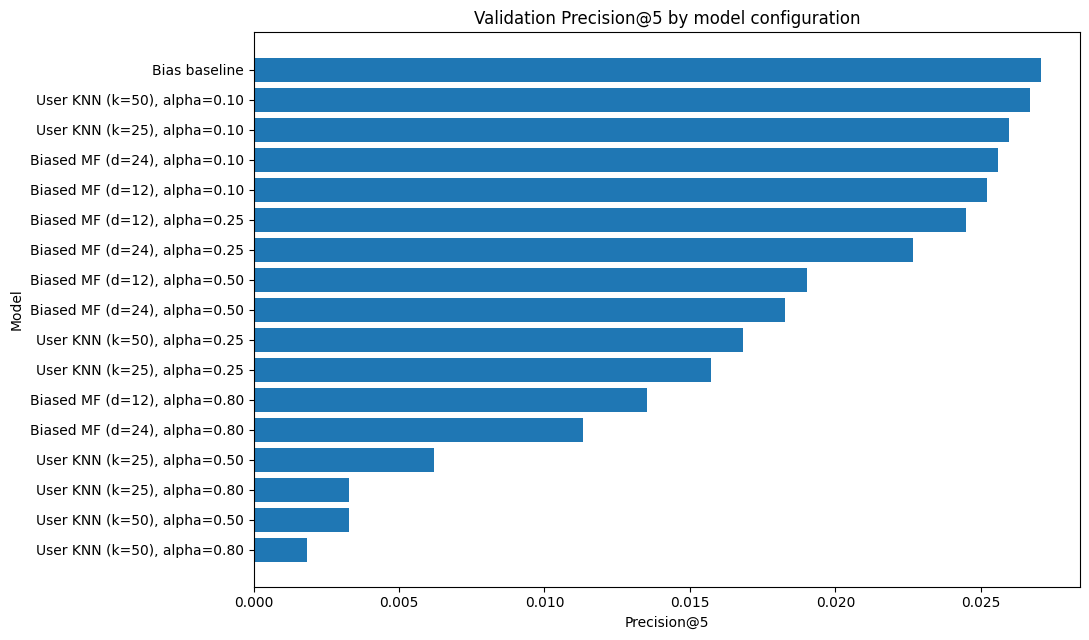

Biased MF (d=12) | best validation epoch: 11
Biased MF (d=24) | best validation epoch: 16


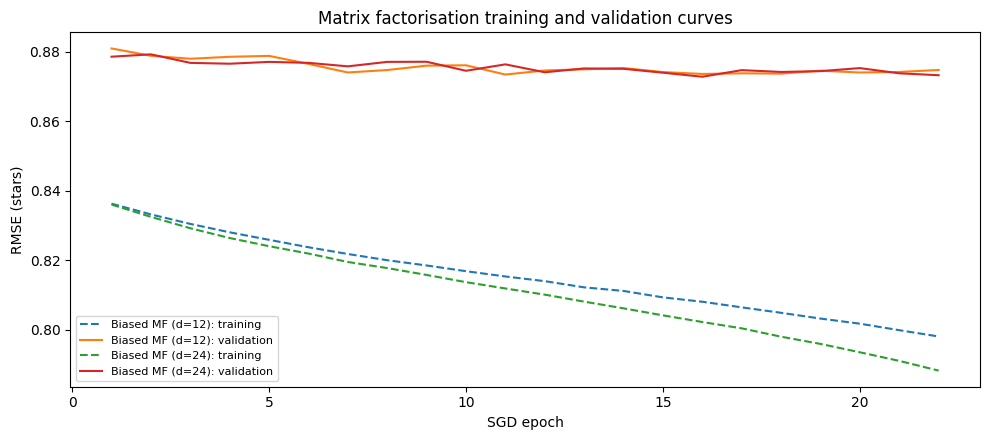

In [ ]:
fig, ax = plt.subplots (figsize = (11, 6.5))
ordered_scores = validation_table.sort_values ("Precision@5")
ax.barh (ordered_scores["Model"], ordered_scores["Precision@5"])
ax.set (title = "Validation Precision@5 by model configuration", xlabel = "Precision@5", ylabel = "Model")
plt.tight_layout ()
plt.show ()

fig, ax = plt.subplots (figsize = (10, 4.5))
for name, model in trained_core_models.items ():
    if isinstance (model, BiasedMatrixFactorisation):
        ax.plot (model.history["Epoch"], model.history["Training RMSE"],
                 linestyle = "--", label = f"{name}: training")
        ax.plot (model.history["Epoch"], model.history["Validation RMSE"],
                 label = f"{name}: validation")
        print (name, "| best validation epoch:", model.best_epoch)
ax.set (title = "Matrix factorisation training and validation curves",
        xlabel = "SGD epoch", ylabel = "RMSE (stars)")
ax.legend (fontsize = 8)
plt.tight_layout ()
plt.show ()

## 10. Final held-out test: all three algorithm families

After fixing the configurations **using validation only**, each family is refitted on `training + validation` ratings. The **validation-selected collaborative model** is the primary deployed model even if the bias-only baseline proves stronger on ranking. Models are then assessed once on the **same untouched test set**, with the original train-defined candidate pool. This lets us report all families transparently without selecting the final model retrospectively by test performance.

MF refits for its **validation-selected number of epochs**; it does not run test-based early stopping. The model choice shown below is therefore a selection decision made *before* test evaluation.

In [ ]:
family_best = {}

for family, prefix in [
    ("Baseline", "Bias baseline"),
    ("KNN", "User KNN"),
    ("MF", "Biased MF")
]:
    subset = validation_table.loc[validation_table["Model"].str.startswith (prefix)]
    family_best[family] = str (subset.iloc[0]["Model"])


def refit_configuration (model_name, observations):
    bias = BiasBaseline ().fit (observations, user_ids, item_ids)
    if model_name == "Bias baseline":
        return bias

    previous = validation_models[model_name]
    original_core = previous.core_model
    strength = previous.collaborative_strength

    if model_name.startswith ("User KNN"):
        core = UserKNN (
            neighbours = original_core.neighbours,
            shrinkage = original_core.shrinkage,
            minimum_overlap = original_core.minimum_overlap
        ).fit (observations, user_ids, item_ids)

    elif model_name.startswith ("Biased MF"):
        core = BiasedMatrixFactorisation (
            factors = original_core.factors,
            epochs = original_core.best_epoch,
            learning_rate = original_core.learning_rate,
            regularisation = original_core.regularisation,
            batch_size = original_core.batch_size,
            seed = RANDOM_SEED
        ).fit (observations, user_ids, item_ids)

    else:
        raise ValueError (f"Unknown model configuration: {model_name}")

    return CalibratedCollaborativeModel (core, bias, strength)


test_models = {}
test_user_results = {}
test_rows = []

for family, configuration in family_best.items ():
    model = refit_configuration (configuration, train_valid)
    test_models[configuration] = model
    summary, per_user = evaluate_model (configuration, model, train_valid, test)
    test_rows.append (summary)
    test_user_results[configuration] = per_user
    print (f"Tested {configuration}: Precision@5 = {summary['Precision@5']:.4f}")

test_table = pd.DataFrame (test_rows).sort_values ("Precision@5", ascending = False)

display (test_table.round (4))
print ("Validation-selected collaborative model:", selected_model_name)
assert selected_model_name in test_models

Tested Bias baseline: Precision@5 = 0.0512
Tested User KNN (k=50), alpha=0.10: Precision@5 = 0.0502
Tested Biased MF (d=24), alpha=0.10: Precision@5 = 0.0485


,Model,RMSE,MAE,Precision@5,Recall@5,Hit Rate@5,NDCG@5,Eligible users,Catalog coverage@5
0,Bias baseline,0.9048,0.6998,0.0512,0.0227,0.2031,0.0562,586,0.0134
1,"User KNN (k=50), alpha=0.10",0.8982,0.6932,0.0502,0.0196,0.1980,0.0547,586,0.0167
2,"Biased MF (d=24), alpha=0.10",0.9034,0.6982,0.0485,0.0220,0.1962,0.0542,586,0.0127


Validation-selected collaborative model: User KNN (k=50), alpha=0.10


### 10.1 Test visualisation and uncertainty

The test table is descriptive evidence; we do **not** change the chosen model in response to it. We also use a paired, user-level bootstrap of the *difference* in Precision@5 between the selected model and baseline, using the same eligible users. The 95% interval expresses **sampling uncertainty conditional on this evaluation protocol**, not proof of real-world user benefits.

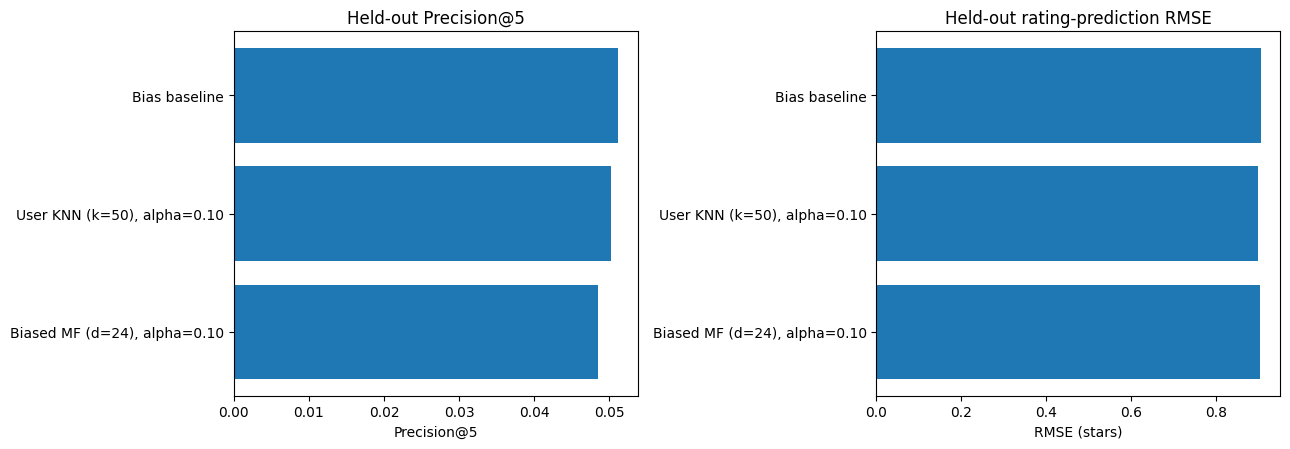

Eligible test users in paired comparison: 586
Selected minus baseline Precision@5: -0.0010
Paired bootstrap 95% interval: [-0.0055, +0.0034]


In [ ]:
fig, axes = plt.subplots (1, 2, figsize = (13, 4.6))
test_plot = test_table.sort_values ("Precision@5")
axes[0].barh (test_plot["Model"], test_plot["Precision@5"])
axes[0].set (title = "Held-out Precision@5", xlabel = "Precision@5")
axes[1].barh (test_plot["Model"], test_plot["RMSE"])
axes[1].set (title = "Held-out rating-prediction RMSE", xlabel = "RMSE (stars)")
plt.tight_layout ()
plt.show ()

baseline_users = test_user_results["Bias baseline"][["userId", "Precision@5"]]
selected_users = test_user_results[selected_model_name][["userId", "Precision@5"]]
paired = baseline_users.merge (
    selected_users, on = "userId", suffixes = ("_baseline", "_selected"),
    validate = "one_to_one"
)
differences = (
    paired["Precision@5_selected"] - paired["Precision@5_baseline"]
).to_numpy ()

bootstrap_rng = np.random.default_rng (RANDOM_SEED)
bootstrap_indices = bootstrap_rng.integers (
    0, len (differences), size = (1000, len (differences))
)
bootstrapped_means = differences[bootstrap_indices].mean (axis = 1)
confidence_limits = np.quantile (bootstrapped_means, [0.025, 0.975])

print (f"Eligible test users in paired comparison: {len (paired)}")
print (f"Selected minus baseline Precision@5: {differences.mean ():+.4f}")
print (f"Paired bootstrap 95% interval: [{confidence_limits[0]:+.4f}, {confidence_limits[1]:+.4f}]")

### 10.2 Interpreting the actual measured results

The next cell synthesises the empirical findings **from this run**, rather than pre-writing favourable conclusions. Report the selected model, baseline comparison, RMSE and eligible user count together. A modest improvement, an inconclusive interval or even worse test performance should be stated candidly.

In [ ]:
selected_test = test_table.set_index ("Model").loc[selected_model_name]
baseline_test = test_table.set_index ("Model").loc["Bias baseline"]

print (f"Validation-selected collaborative model: {selected_model_name}")
print (f"Held-out Precision@5: {selected_test['Precision@5']:.4f}")
print (f"Held-out Recall@5: {selected_test['Recall@5']:.4f}")
print (f"Held-out Hit Rate@5: {selected_test['Hit Rate@5']:.4f}")
print (f"Held-out NDCG@5: {selected_test['NDCG@5']:.4f}")
print (f"Held-out RMSE: {selected_test['RMSE']:.4f} stars")
print (f"Eligible test users: {int (selected_test['Eligible users'])}")

if selected_test["Precision@5"] > baseline_test["Precision@5"]:
    print ("The selected collaborative model beats the baseline on held-out Precision@5.")
elif selected_test["Precision@5"] == baseline_test["Precision@5"]:
    print ("The selected collaborative model ties the baseline on held-out Precision@5.")
else:
    print ("The baseline is stronger on held-out Precision@5; collaborative filtering is still required by the task.")

if confidence_limits[0] <= 0 <= confidence_limits[1]:
    print ("Paired 95% interval includes zero: the observed difference is uncertain under this bootstrap.")
else:
    print ("Paired 95% interval excludes zero under this observational evaluation protocol.")

Validation-selected collaborative model: User KNN (k=50), alpha=0.10
Held-out Precision@5: 0.0502
Held-out Recall@5: 0.0196
Held-out Hit Rate@5: 0.1980
Held-out NDCG@5: 0.0547
Held-out RMSE: 0.8982 stars
Eligible test users: 586
The baseline is stronger on held-out Precision@5; collaborative filtering is still required by the task.
Paired 95% interval includes zero: the observed difference is uncertain under this bootstrap.


## 11. Fit the selected model to all ratings for demonstration

Only **after** the untouched test evaluation do we refit on the full cleaned ratings for practical use. A real system would train on all ratings currently available. This final training step must not be used to amend the already-reported held-out metrics.

For recommending, we filter the user's rated movies, calculate raw scores, sort, and return **exactly five** distinct, previously unrated movie titles. The displayed `Predicted stars` value is clipped/rounded for readability **after ranking**. These are *predicted preferences*, not real user feedback.

In [ ]:
final_model = refit_configuration (selected_model_name, ratings)
final_raw_scores = final_model.score_matrix ()
full_history = ratings.groupby ("userId")["movieId"].agg (set).to_dict ()
full_movie_counts = ratings.groupby ("movieId").size ()
final_eligible_ids = np.sort (
    full_movie_counts.loc[full_movie_counts >= MIN_ITEM_RATINGS].index.to_numpy ()
)
final_candidate_positions = item_index.get_indexer (final_eligible_ids)
movie_details = movie_catalog.set_index ("movieId")


def recommend_existing_user (user_id, k = TOP_K):
    if user_id not in full_history:
        raise ValueError ("Unknown user ID. Select an ID from the MovieLens ratings file.")

    ranked_ids, unrounded_scores = rank_top_five (
        final_raw_scores, user_index.get_loc (user_id),
        full_history[user_id], final_candidate_positions, k = k
    )

    results = pd.DataFrame ({
        "Rank": np.arange (1, k + 1),
        "movieId": ranked_ids,
        "Predicted stars": np.round (np.clip (unrounded_scores, 0.5, 5.0), 2)
    })
    results["Title"] = results["movieId"].map (movie_details["title"])
    results["Genres"] = results["movieId"].map (movie_details["genres"])
    results["Rating count"] = results["movieId"].map (full_movie_counts)
    assert not set (results["movieId"]) & full_history[user_id]
    return results[["Rank", "movieId", "Title", "Genres", "Predicted stars", "Rating count"]]


existing_user_example = recommend_existing_user (user_id = 1)
display (existing_user_example)
print ("Model:", selected_model_name)
print ("Five distinct, previously unrated recommendations verified for MovieLens User 1.")

,Rank,movieId,Title,Genres,Predicted stars,Rating count
0,1,318,"Shawshank Redemption, The (1994)",Crime|Drama,5.00,317
1,2,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.99,97
2,3,858,"Godfather, The (1972)",Crime|Drama,4.96,192
3,4,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.96,129
4,5,48516,"Departed, The (2006)",Crime|Drama|Thriller,4.93,107


Model: User KNN (k=50), alpha=0.10
Five distinct, previously unrated recommendations verified for MovieLens User 1.


## 12. Optional extension: new-user onboarding and genre-assisted hybrid

A brand-new user has no collaborative factors or neighbourhood relationships. The following **optional hybrid cold-start extension** accepts three or more **movie IDs with explicit ratings**. It:

1. measures agreement between the new user's ratings and historical users on **co-rated anchor movies** (requiring at least two shared anchors);
2. computes a weighted residual recommendation signal from positively similar neighbours;
3. uses **movie genres as a small supplementary signal**, especially when overlap is weak;
4. falls back to the **regularised popularity/quality baseline** where neighbour evidence is absent.

This extension is deliberately separate from the primary three-model comparison and **is not presented as a tested algorithm**. It is a demonstration of how content information might alleviate *new-user* cold start. It does **not** completely solve *new-movie* cold start or guarantee useful results from just three ratings.

In [ ]:
final_bias = BiasBaseline ().fit (ratings, user_ids, item_ids)

rating_user_positions = user_index.get_indexer (ratings["userId"])
rating_item_positions = item_index.get_indexer (ratings["movieId"])

interaction_mask = sparse.csr_matrix (
    (np.ones (len (ratings)), (rating_user_positions, rating_item_positions)),
    shape = (len (user_ids), len (item_ids))
)

observed_residuals = (
    ratings["rating"].to_numpy () - final_bias.predict_raw (ratings)
)
residual_history = sparse.csr_matrix (
    (observed_residuals, (rating_user_positions, rating_item_positions)),
    shape = (len (user_ids), len (item_ids))
)

genre_features = (
    movie_catalog.set_index ("movieId")["genres"]
    .replace ("(no genres listed)", "")
    .str.get_dummies (sep = "|")
    .reindex (item_ids, fill_value = 0)
)
genre_matrix = genre_features.to_numpy (dtype = float)


def recommend_new_user (movie_ratings, k = TOP_K):
    if len (movie_ratings) < 3:
        raise ValueError ("Please provide at least three movieId: rating pairs.")

    input_ids = np.array (list (movie_ratings.keys ()), dtype = int)
    input_stars = np.array (list (movie_ratings.values ()), dtype = float)

    if (item_index.get_indexer (input_ids) < 0).any ():
        raise ValueError ("One or more movie IDs do not exist in movies.csv.")
    if not (
        np.all ((input_stars >= 0.5) & (input_stars <= 5.0))
        and np.all (np.isclose (input_stars * 2, np.round (input_stars * 2)))
    ):
        raise ValueError ("Use ratings between 0.5 and 5.0 in increments of 0.5.")

    anchor_positions = item_index.get_indexer (input_ids)
    item_base = final_bias.global_mean + final_bias.item_bias[anchor_positions]
    new_user_offset = np.sum (input_stars - item_base) / (len (input_stars) + 5)
    new_residuals = input_stars - item_base - new_user_offset

    anchor_residuals = residual_history[:, anchor_positions].toarray ()
    anchor_mask = interaction_mask[:, anchor_positions].toarray ()
    common_counts = anchor_mask.sum (axis = 1)
    dot_products = anchor_residuals @ new_residuals
    denominator = np.linalg.norm (anchor_residuals, axis = 1) * np.linalg.norm (new_residuals)
    similarities = np.divide (
        dot_products, denominator,
        out = np.zeros_like (dot_products), where = denominator > 1e-12
    )
    similarities *= common_counts / (common_counts + 2.0)
    similarities[common_counts < 2] = 0.0
    similarities = np.maximum (similarities, 0.0)

    neighbour_positions = np.argsort (-similarities)[:40]
    neighbour_positions = neighbour_positions[similarities[neighbour_positions] > 0]
    weights = np.zeros (len (user_ids), dtype = float)
    weights[neighbour_positions] = similarities[neighbour_positions]

    numerator = np.asarray (weights @ residual_history).ravel ()
    support = np.asarray (weights @ interaction_mask).ravel ()
    neighbour_signal = np.divide (
        numerator, support + 1.5,
        out = np.zeros_like (numerator), where = support > 1e-12
    )

    prior = final_bias.global_mean + final_bias.item_bias + new_user_offset
    genre_signal_weights = (input_stars - 3.0)
    genre_profile = (
        genre_matrix[anchor_positions].T @ genre_signal_weights
        / max (np.sum (np.abs (genre_signal_weights)), 1e-10)
    )
    genres_per_item = np.maximum (genre_matrix.sum (axis = 1), 1)
    genre_bonus = 0.35 * (genre_matrix @ genre_profile) / np.sqrt (genres_per_item)
    hybrid_scores = prior + neighbour_signal + genre_bonus

    eligible_positions = item_index.get_indexer (final_eligible_ids)
    allowed_positions = eligible_positions[~np.isin (final_eligible_ids, input_ids)]
    chosen = allowed_positions[np.argsort (-hybrid_scores[allowed_positions])[:k]]
    chosen_ids = item_ids[chosen]

    results = pd.DataFrame ({
        "Rank": np.arange (1, k + 1),
        "movieId": chosen_ids,
        "Title": movie_details.loc[chosen_ids, "title"].to_numpy (),
        "Genres": movie_details.loc[chosen_ids, "genres"].to_numpy (),
        "Indicative stars": np.round (np.clip (hybrid_scores[chosen], 0.5, 5.0), 2),
        "Rating count": full_movie_counts.reindex (chosen_ids).to_numpy ()
    })

    return results, len (neighbour_positions)


new_user_input = {
    1: 5.0,     # Toy Story (1995)
    2: 4.0,     # Jumanji (1995)
    6: 4.5,     # Heat (1995)
    7: 2.0      # Father of the Bride Part II (1995)
}

new_user_example, matched_neighbours = recommend_new_user (new_user_input)
print ("Positive historical neighbours supporting the new-user profile:", matched_neighbours)
display (new_user_example)

Positive historical neighbours supporting the new-user profile: 40


,Rank,movieId,Title,Genres,Indicative stars,Rating count
0,1,78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,4.95,55
1,2,58559,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,4.77,149
2,3,1198,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure,4.76,200
3,4,720,Wallace & Gromit: The Best of Aardman Animatio...,Adventure|Animation|Comedy,4.75,27
4,5,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,4.74,279


## 13. Academic discussion, threats to validity and practical implications

**1. Rating prediction and ranking are different questions.** A model can predict observed stars accurately yet fail to retrieve the five positively rated held-out films. Precision@5 is prioritised because the brief explicitly asks for **five recommendations**. RMSE/MAE remain useful secondary diagnostics.

**2. Offline relevance is incomplete.** Only a tiny fraction of films is rated by each user. Not retrieved in a held-out log does **not** imply irrelevance. A relevant title that was never rated cannot be credited as a hit, depressing observed Precision@5. These metrics are not equivalent to an A/B test or measured future user satisfaction.

**3. Chronological splitting is per user, not globally causal.** Earlier interactions of one user can occur after the withheld ratings of another user. This design tests within-user historical ordering, but a strict production rollout would require a global temporal split with newly arriving users/items.

**4. Survivorship and selection bias.** MovieLens only includes users with at least 20 ratings. It does not represent truly inactive users, current subscribers or the entire entertainment market. Data were gathered up to 2018, so the system is a methodological prototype rather than a current streaming catalogue.

**5. Popularity and coverage trade-off.** The five-training-rating threshold suppresses unstable item estimates but excludes part of the long tail. Report *eligible catalogue size* and catalogue coverage alongside Precision@5. Future work could evaluate novelty, diversity and user-group fairness.

**6. Overfitting and tuning budget.** MF can fit the observed interactions increasingly well while validation error plateaus. The tuning grid here is intentionally small. Running additional combinations after seeing test results would invalidate the held-out comparison.

**7. Cold-start scope.** Existing-user recommendations are collaborative; the separate new-user demonstration incorporates genre content and is not included in the main controlled test. A convincing deployment evaluation would collect feedback from newly registered users and compare onboarding variants.

**8. Interpretability.** The baseline is straightforward, KNN provides some neighbour-based explanation, and MF has latent dimensions that are not guaranteed to correspond to interpretable genres or themes.

**9. Data ethics.** User IDs are anonymous, and the release contains no demographic data. Do not infer sensitive personal characteristics or present estimated ratings as observations. Preserve the GroupLens attribution and licensing conditions.

## 14. Conclusion, outputs and reproducibility checks

The conclusions must follow the measured validation/test comparison, not the preferred complexity of any method. The final deployable model is intentionally constrained to collaborative filtering because the assignment requires it, even if the bias-only reference wins some metrics. The final study provides a valid **top-five recommender**, explicit model-selection evidence, a fixed test protocol, and a clear discussion of what offline observations cannot establish.

All tables below are saved to `outputs/` for insertion into a group presentation or report. The executable notebook is the main academic artefact; the HTML rendering is a convenient read-only companion.

In [ ]:
validation_table.to_csv (OUTPUT_DIR / "validation_comparison.csv", index = False)
test_table.to_csv (OUTPUT_DIR / "heldout_test_comparison.csv", index = False)
existing_user_example.to_csv (OUTPUT_DIR / "top5_existing_user_1.csv", index = False)
new_user_example.to_csv (OUTPUT_DIR / "top5_new_user.csv", index = False)

study_metadata = {
    "dataset": "MovieLens ml-latest-small",
    "random_seed": RANDOM_SEED,
    "split": "Per-user chronological 70/10/20 (floor rounding)",
    "train_ratings": len (train),
    "validation_ratings": len (valid),
    "test_ratings": len (test),
    "eligible_candidate_movies_from_training": len (eligible_item_ids),
    "minimum_training_ratings_per_candidate": MIN_ITEM_RATINGS,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "selection_metric": "Validation Precision@5, NDCG@5, then RMSE",
    "validation_selected_model": selected_model_name,
    "selection_eligibility": "Only collaborative KNN and MF models, not the bias baseline",
    "selected_test_precision_at_5": float (selected_test["Precision@5"]),
    "selected_test_rmse": float (selected_test["RMSE"]),
    "eligible_test_users": int (selected_test["Eligible users"]),
    "test_precision_at_5_difference_vs_baseline": float (differences.mean ()),
    "test_difference_bootstrap_95pct": confidence_limits.tolist ()
}

(OUTPUT_DIR / "study_metadata.json").write_text (
    json.dumps (study_metadata, indent = 2), encoding = "utf-8"
)

assert len (existing_user_example) == TOP_K
assert len (new_user_example) == TOP_K
assert existing_user_example["movieId"].is_unique
assert new_user_example["movieId"].is_unique
assert not (set (existing_user_example["movieId"]) & full_history[1])
assert not (set (new_user_example["movieId"]) & set (new_user_input))
assert all (name in test_models for name in [selected_model_name, "Bias baseline"])

for output in sorted (OUTPUT_DIR.glob ("*")):
    print (" •", output.name)

 • cleaned_movie_catalog.csv
 • cleaned_ratings.csv
 • heldout_test_comparison.csv
 • study_metadata.json
 • top5_existing_user_1.csv
 • top5_new_user.csv
 • validation_comparison.csv


## 15. References and acknowledgement

1. GroupLens Research. (2018). *MovieLens ml-latest-small dataset and README*. University of Minnesota. https://files.grouplens.org/datasets/movielens/ml-latest-small-README.html
2. Harper, F. M., & Konstan, J. A. (2015). The MovieLens datasets: History and context. *ACM Transactions on Interactive Intelligent Systems, 5*(4), Article 19. https://doi.org/10.1145/2827872

